# 模板9-流程挖掘

# 1、导入IEEE XES格式数据

In [8]:
##导入IEEE XES格式数据
#IEEE XES是一种存储日志数据的标准格式。
from pm4py.objects.log.importer.xes import importer as xes_importer

log = xes_importer.apply('./running-example.xes')
print(log)

parsing log, completed traces ::   0%|          | 0/6 [00:00<?, ?it/s]

[{'attributes': {'concept:name': '3', 'creator': 'Fluxicon Nitro'}, 'events': [{'concept:name': 'register request', 'org:resource': 'Pete', 'time:timestamp': datetime.datetime(2010, 12, 30, 14, 32, tzinfo=datetime.timezone.utc), 'Activity': 'register request', 'Resource': 'Pete', 'Costs': '50'}, '..', {'concept:name': 'pay compensation', 'org:resource': 'Ellen', 'time:timestamp': datetime.datetime(2011, 1, 15, 10, 45, tzinfo=datetime.timezone.utc), 'Activity': 'pay compensation', 'Resource': 'Ellen', 'Costs': '200'}]}, '....', {'attributes': {'concept:name': '4', 'creator': 'Fluxicon Nitro'}, 'events': [{'concept:name': 'register request', 'org:resource': 'Pete', 'time:timestamp': datetime.datetime(2011, 1, 6, 15, 2, tzinfo=datetime.timezone.utc), 'Activity': 'register request', 'Resource': 'Pete', 'Costs': '50'}, '..', {'concept:name': 'reject request', 'org:resource': 'Ellen', 'time:timestamp': datetime.datetime(2011, 1, 12, 15, 44, tzinfo=datetime.timezone.utc), 'Activity': 'reject 

In [9]:
print('The first trace in the log: \n', log[0])
print('-' * 80)
print('The first event of the first trace: \n', log[0][0])

The first trace in the log: 
 {'attributes': {'concept:name': '3', 'creator': 'Fluxicon Nitro'}, 'events': [{'concept:name': 'register request', 'org:resource': 'Pete', 'time:timestamp': datetime.datetime(2010, 12, 30, 14, 32, tzinfo=datetime.timezone.utc), 'Activity': 'register request', 'Resource': 'Pete', 'Costs': '50'}, '..', {'concept:name': 'pay compensation', 'org:resource': 'Ellen', 'time:timestamp': datetime.datetime(2011, 1, 15, 10, 45, tzinfo=datetime.timezone.utc), 'Activity': 'pay compensation', 'Resource': 'Ellen', 'Costs': '200'}]}
--------------------------------------------------------------------------------
The first event of the first trace: 
 {'concept:name': 'register request', 'org:resource': 'Pete', 'time:timestamp': datetime.datetime(2010, 12, 30, 14, 32, tzinfo=datetime.timezone.utc), 'Activity': 'register request', 'Resource': 'Pete', 'Costs': '50'}


In [10]:
log[0:2:2][:3]

[{'attributes': {'concept:name': '3', 'creator': 'Fluxicon Nitro'}, 'events': [{'concept:name': 'register request', 'org:resource': 'Pete', 'time:timestamp': datetime.datetime(2010, 12, 30, 14, 32, tzinfo=datetime.timezone.utc), 'Activity': 'register request', 'Resource': 'Pete', 'Costs': '50'}, '..', {'concept:name': 'pay compensation', 'org:resource': 'Ellen', 'time:timestamp': datetime.datetime(2011, 1, 15, 10, 45, tzinfo=datetime.timezone.utc), 'Activity': 'pay compensation', 'Resource': 'Ellen', 'Costs': '200'}]}]

In [11]:
print(type(log))
print(type(log[0]))
print(type(log[0][0]))

<class 'pm4py.objects.log.obj.EventLog'>
<class 'pm4py.objects.log.obj.Trace'>
<class 'pm4py.objects.log.obj.Event'>


In [12]:
print('Length of the log is %d' %(len(log)))
print('Length of the first trace is %d' %(len(log[0])))
print('Length of the first event is %d' %(len(log[0][0])))

Length of the log is 6
Length of the first trace is 9
Length of the first event is 6


In [13]:
# 导出XES文件
from pm4py.objects.log.exporter.xes import exporter as xes_exporter
xes_exporter.apply(log, "./exportedLog.xes")

exporting log, completed traces ::   0%|          | 0/6 [00:00<?, ?it/s]

# 2、流程发现和流程监控

# Directly-Follows Graph和流程监控的演示

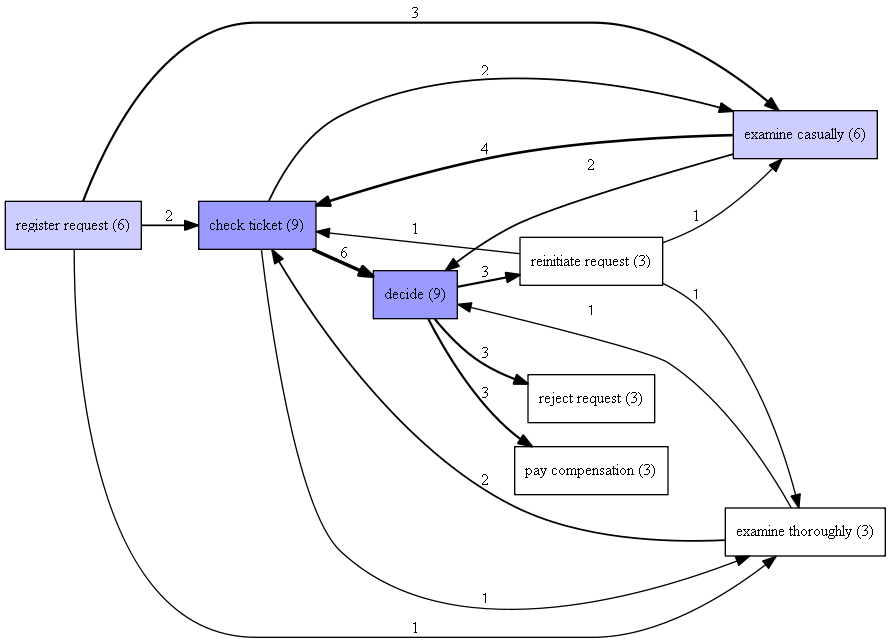

In [14]:
from pm4py.algo.discovery.dfg import algorithm as dfg_discovery
from pm4py.visualization.dfg import visualizer as dfg_visualization

dfg = dfg_discovery.apply(log)
gviz = dfg_visualization.apply(dfg, log=log, variant=dfg_visualization.Variants.FREQUENCY)
dfg_visualization.view(gviz)

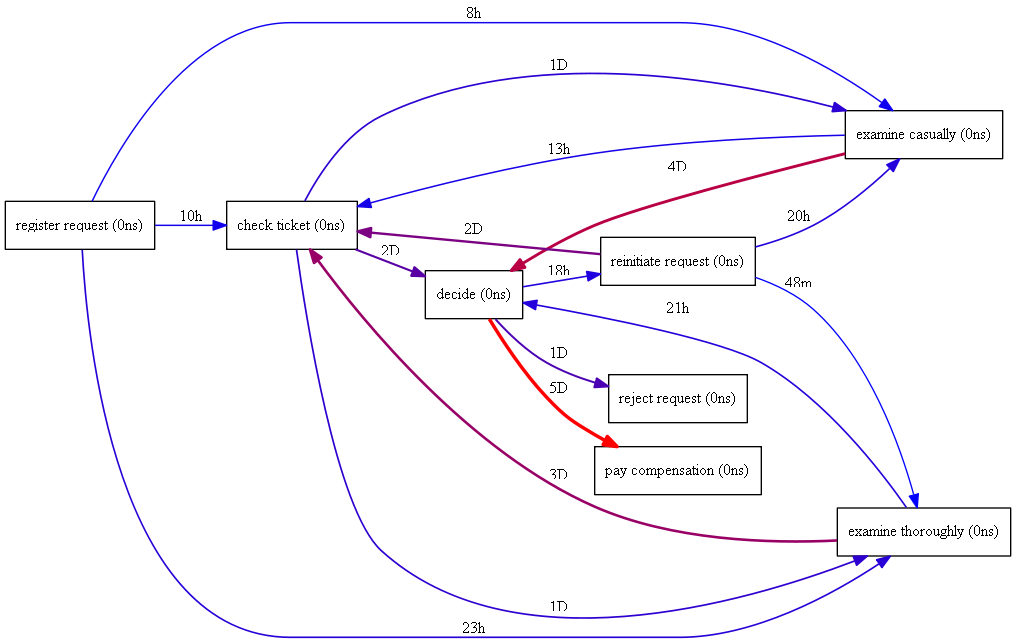

In [15]:
#添加流程转换耗时信息
from pm4py.algo.discovery.dfg import algorithm as dfg_discovery
from pm4py.visualization.dfg import visualizer as dfg_visualization

dfg = dfg_discovery.apply(log, variant=dfg_discovery.Variants.PERFORMANCE)
gviz = dfg_visualization.apply(dfg, log=log, variant=dfg_visualization.Variants.PERFORMANCE)
dfg_visualization.view(gviz)